# LAPORAN PRAKTIKUM MACHINE LEARNING
**Dosen Pengampu:** Asep Erlan Maulana S.Kom., M.Kom  

**Disusun Oleh:**
* **Nama:** Miftakhul Fal’ah
* **NIM:** 241011400237
* **Kelas:** 05TPLP018

---
## 1. Import Library & Setup Environment
Pada tahap ini, dilakukan pengimporan seluruh modul dan pustaka (*library*) Python yang dibutuhkan untuk pemrosesan data, pemodelan *Machine Learning*, serta visualisasi grafik.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Tool Machine Learning dari Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Konfigurasi Tampilan Tema Gambar
sns.set_theme(style="whitegrid")
%matplotlib inline

## 2. Load Data & Profiling Dataset
Memuat dataset `Social_media_impact_on_life.csv` serta melakukan identifikasi awal terhadap struktur baris, kolom, tipe data, serta statistik deskriptif dari fitur-fitur numerik.

In [2]:
# Load dataset
df = pd.read_csv('Social_media_impact_on_life.csv')

print("--- 5 Baris Pertama Dataset ---")
display(df.head())

print("\n--- Informasi Tipe Data dan Missing Value ---")
df.info()

print("\n--- Ringkasan Statistik Data Numerik ---")
display(df.describe())

--- 5 Baris Pertama Dataset ---


,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial



--- Informasi Tipe Data dan Missing Value ---
<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   str    
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   str    
 3   Academic_Level               4500 non-null   str    
 4   Primary_Platform             4500 non-null   str    
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours          4500 non-null   float64
 7   Device_Type                  4500 non-null   str    
 8   Sleep_Duration_Hours         4500 non-null   float64
 9   Sleep_Quality_Score          4500 non-null   int64  
 10  Late_Night_Usage             4500 non-null   bool   
 11  Social_Comparison_Frequency  4500 non-null   str    
 12  Perceived_Stress_Score       4454 non-nu

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
count,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4454.000000,4500.000000,4415.000000
mean,18.703333,5.295933,1.796844,6.701333,2.472000,13.512124,79.873111,3.429282
std,1.981182,2.604497,0.699245,1.189998,1.030484,7.072859,12.876044,0.392662
min,15.000000,0.900000,0.000000,3.000000,1.000000,0.000000,32.000000,1.900000
25%,17.000000,3.400000,1.300000,6.000000,2.000000,9.000000,72.000000,3.200000
50%,19.000000,4.700000,1.800000,6.800000,3.000000,13.000000,82.000000,3.460000
75%,20.000000,6.600000,2.300000,7.500000,3.000000,18.000000,89.000000,3.720000
max,26.000000,14.000000,4.500000,10.500000,5.000000,40.000000,98.000000,4.000000


## 3. Exploratory Data Analysis (EDA)
Visualisasi distribusi variabel target `Overall_Impact` untuk mengetahui keseimbangan atau ketidakseimbangan kelas (*imbalanced data*) pada dataset.

C:\Users\Miftakhul Fal'ah\AppData\Local\Temp\ipykernel_10084\2290353015.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Overall_Impact', palette='viridis')


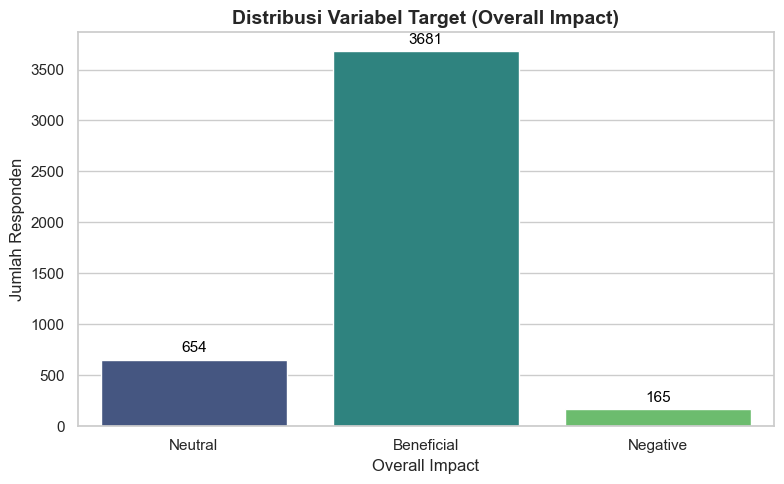

In [3]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='Overall_Impact', palette='viridis')
plt.title('Distribusi Variabel Target (Overall Impact)', fontsize=14, fontweight='bold')
plt.xlabel('Overall Impact', fontsize=12)
plt.ylabel('Jumlah Responden', fontsize=12)

# Menambahkan label angka di atas setiap bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=11, color='black', xytext=(0, 3),
                textcoords='offset points')

plt.tight_layout()
plt.show()

## 4. Preprocessing Data & Pipeline Transformation
Langkah-langkah penyiapan data (*data preprocessing*):
1. **Memisahkan Fitur ($X$) dan Target ($y$):** Menghapus variabel non-prediktif (`Student_ID`).
2. **Mengubah Tipe Data Kategorikal:** Mengonversi variabel kategorikal secara eksplisit ke tipe `string`.
3. **Pembersihan Missing Value (Imputation):** Pengisian nilai kosong menggunakan *median* untuk variabel numerik dan *mode* (*most frequent*) untuk variabel kategorikal.
4. **Feature Scaling & Encoding:** Standardisasi nilai numerik (`StandardScaler`) dan transformasi variabel kategorikal menjadi *one-hot vectors* (`OneHotEncoder`).
5. **Data Splitting:** Membagi dataset menjadi **80% Data Latih (*Train*)** dan **20% Data Uji (*Test*)** secara terstrata (`stratify=y`).

In [4]:
# Memisahkan Fitur dan Target
target_col = 'Overall_Impact'
X = df.drop(columns=['Student_ID', target_col])
y = df[target_col]

# Identifikasi Kolom Numerik dan Kategorikal
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category', 'bool', 'string']).columns.tolist()

# Konversi tipe data kategorikal ke string secara eksplisit
X[cat_cols] = X[cat_cols].astype(str)

# Preprocessing Pipeline untuk Numerik
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocessing Pipeline untuk Kategorikal
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Penggabungan Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

# Pembagian Data Train dan Test dengan Stratify
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Jumlah Data Latih (Train): {X_train.shape[0]} baris")
print(f"Jumlah Data Uji (Test)  : {X_test.shape[0]} baris")

Jumlah Data Latih (Train): 3600 baris
Jumlah Data Uji (Test)  : 900 baris


## 5. Pelatihan & Evaluasi Model 1: Decision Tree
Membuat *pipeline* untuk algoritma **Decision Tree Classifier**, melatih model dengan data latih, dan mengevaluasi kinerja prediksinya pada data uji.

In [5]:
# Pipeline Decision Tree
dt_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# Training
dt_model.fit(X_train, y_train)

# Prediksi
y_pred_dt = dt_model.predict(X_test)

# Evaluasi
acc_dt = accuracy_score(y_test, y_pred_dt)
print(f"Akurasi Decision Tree: {acc_dt * 100:.2f}%\n")
print("--- Classification Report (Decision Tree) ---")
print(classification_report(y_test, y_pred_dt))

Akurasi Decision Tree: 96.44%

--- Classification Report (Decision Tree) ---
              precision    recall  f1-score   support

  Beneficial       0.99      0.98      0.98       736
    Negative       0.83      0.91      0.87        33
     Neutral       0.86      0.90      0.88       131

    accuracy                           0.96       900
   macro avg       0.90      0.93      0.91       900
weighted avg       0.97      0.96      0.96       900



## 6. Pelatihan & Evaluasi Model 2: Random Forest
Membuat *pipeline* untuk algoritma *ensemble* **Random Forest Classifier** (dengan 100 pohon keputusan), melatih model, dan mengevaluasi kinerjanya.

In [6]:
# Pipeline Random Forest
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

# Training
rf_model.fit(X_train, y_train)

# Prediksi
y_pred_rf = rf_model.predict(X_test)

# Evaluasi
acc_rf = accuracy_score(y_test, y_pred_rf)
print(f"Akurasi Random Forest: {acc_rf * 100:.2f}%\n")
print("--- Classification Report (Random Forest) ---")
print(classification_report(y_test, y_pred_rf))

Akurasi Random Forest: 96.89%

--- Classification Report (Random Forest) ---
              precision    recall  f1-score   support

  Beneficial       0.98      0.99      0.98       736
    Negative       0.94      0.91      0.92        33
     Neutral       0.91      0.88      0.89       131

    accuracy                           0.97       900
   macro avg       0.94      0.92      0.93       900
weighted avg       0.97      0.97      0.97       900



## 7. Visualisasi Perbandingan Confusion Matrix
Membuat matriks konfusi (*Confusion Matrix*) untuk membandingkan jumlah hasil prediksi benar vs salah dari kedua algoritma.

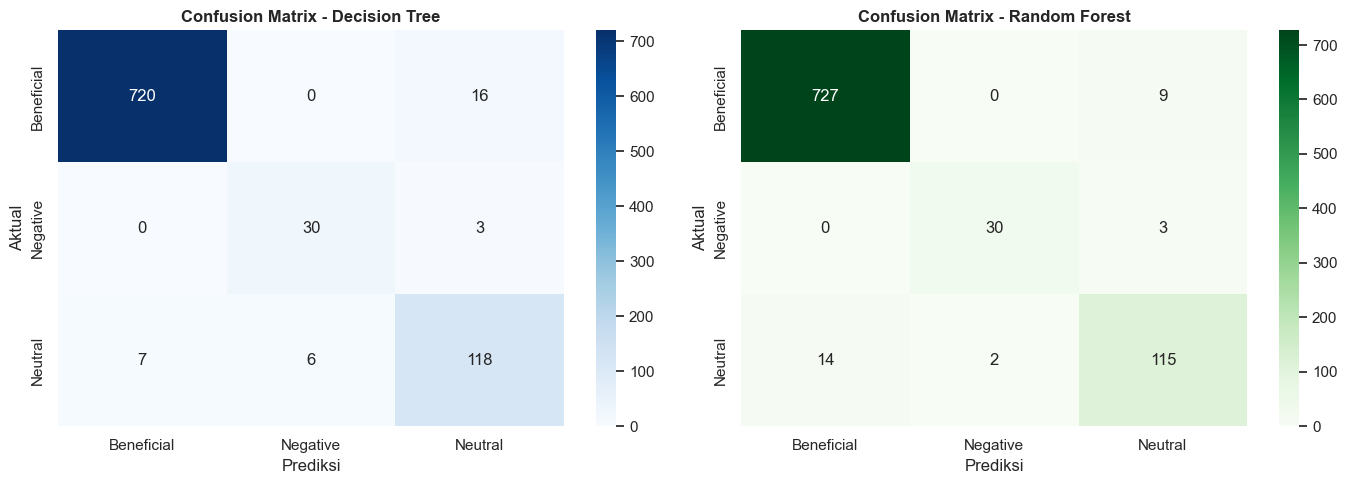

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Mengambil daftar label kelas
labels_classes = dt_model.classes_

# Heatmap Confusion Matrix Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=labels_classes)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=labels_classes, yticklabels=labels_classes)
axes[0].set_title('Confusion Matrix - Decision Tree', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

# Heatmap Confusion Matrix Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=labels_classes)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=labels_classes, yticklabels=labels_classes)
axes[1].set_title('Confusion Matrix - Random Forest', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()

## 8. Analisis Fitur Terpenting (Feature Importance)
Mengekstrak nilai bobot *importance* dari model **Random Forest** untuk mengidentifikasi 10 fitur utama yang paling dominan mempengaruhi variabel target `Overall_Impact`.

C:\Users\Miftakhul Fal'ah\AppData\Local\Temp\ipykernel_10084\3986718228.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_df.head(10), x='Importance', y='Feature', palette='magma')


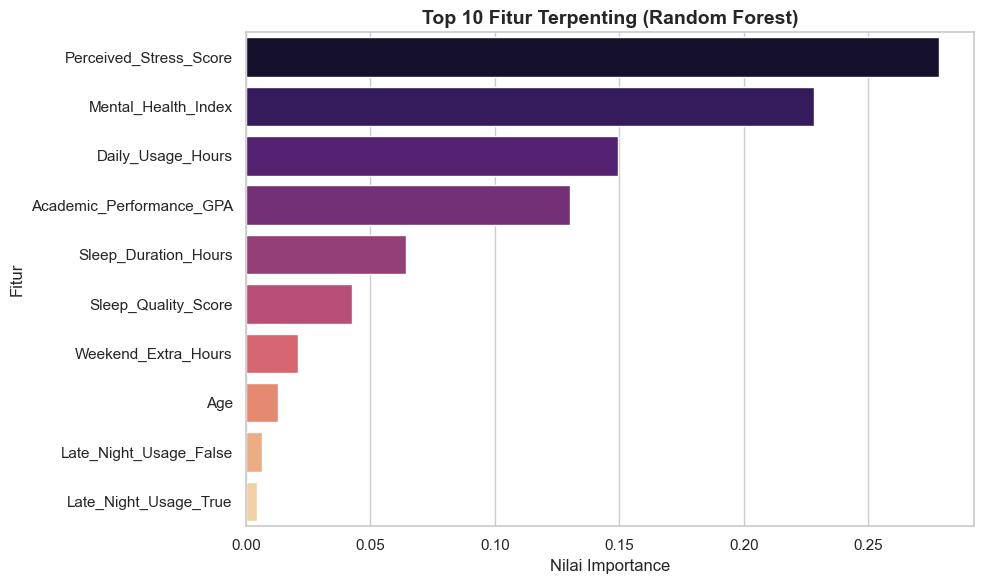

In [8]:
# Ekstraksi nama kolom hasil One-Hot Encoding
ohe_cols = rf_model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols)
all_feature_names = num_cols + list(ohe_cols)

# Ekstraksi nilai importance dari Random Forest
importances = rf_model.named_steps['classifier'].feature_importances_

feature_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plotting Bar Chart Top 10 Fitur
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_df.head(10), x='Importance', y='Feature', palette='magma')
plt.title('Top 10 Fitur Terpenting (Random Forest)', fontsize=14, fontweight='bold')
plt.xlabel('Nilai Importance', fontsize=12)
plt.ylabel('Fitur', fontsize=12)
plt.tight_layout()
plt.show()

## 9. Kesimpulan & Analisis Hasil
1. **Performa Model:** Algoritma **Random Forest** memiliki akurasi yang lebih unggul (**96.89%**) dibandingkan **Decision Tree** (**96.44%**).
2. **Keseimbangan Prediksi:** Random Forest terbukti lebih baik dalam memprediksi kelas minoritas (*Negative* dan *Neutral*).
3. **Fitur Dominan:** Indikator psikologis seperti `Perceived_Stress_Score` (skor tingkat stres) dan `Mental_Health_Index` (indeks kesehatan mental) serta nilai akademis (`Academic_Performance_GPA`) merupakan faktor terpenting dalam menentukan dampak media sosial terhadap kehidupan siswa/mahasiswa.